In [5]:
import os
import pandas as pd

REPO_URL = "https://github.com/shrfr/nafld-fibrosis-prediction.git"
REPO_DIR = "nafld-fibrosis-prediction"

# When the notebook is opened in Colab from GitHub, the repo files aren't there yet, so clone it
if not os.path.exists("data/NAFLD.xlsx"):
    if not os.path.exists(REPO_DIR):
        !git clone {REPO_URL}
    %cd {REPO_DIR}

path = "data/NAFLD.xlsx"
xls = pd.ExcelFile(path)
print(xls.sheet_names)

['Sheet1', 'Sheet2', 'Sheet3']


In [6]:
sheets = pd.read_excel(xls, sheet_name=None)  # dict: {sheet name: DataFrame}

for name, d in sheets.items():
    print("=" * 60)
    print(f"{name} | rows: {d.shape[0]}, columns: {d.shape[1]}")
    print("Non-empty cells:", int(d.notna().sum().sum()))

Sheet1 | rows: 605, columns: 62
Non-empty cells: 31781
Sheet2 | rows: 0, columns: 0
Non-empty cells: 0
Sheet3 | rows: 0, columns: 0
Non-empty cells: 0


**Thus from here , we get to know that there is no data present in sheet2 and sheet3 so we have to work with only sheet1 data.**

In [7]:
# Loading Sheet1
path = "/content/drive/MyDrive/NAFLD_Proj/NAFLD.xlsx"   # your actual file name

df = pd.read_excel(path, sheet_name="Sheet1")
print(df.shape)
df.head()

(605, 62)


,Patient No.,Age,"Gender (Female=1, Male=2)",Height,Weight,Body Mass Index,Waist Circumference,Hip Circumference,Systolic Blood Pressure,Diastolic Blood Pressure,...,Activity,Fibrosis,NAS score according to Kleiner,"NAS score>=4 and Fibrosis>=2 (If NAS score>=4 and Fibrosis>=2 = 1, If not = 0)","Fibrosis status (No=0, Yes=1) (Fibrosis 1 and above, there is Fibrosis)","Significant Fibrosis (No=0, Yes=1) (If Fibrosis 2 and above, there is Significant Fibrosis)","Advanced Fibrosis (No=0, Yes=1) (If Fibrosis is 3 and above, there is Advanced Fibrosis)","Cirrhosis (No=0, Yes=1) (If Fibrosis is 4, there is Cirrhosis)","Diagnosis according to SAF (NASH=1, NAFL=2)","Type of Disease (Mild illness=1, Severe illness=2)"
0,1,60,1,150,80,35.56,119.0,104.0,135,77,...,2,1,4,1,1,0,0,0,1,2
1,2,55,1,154,73,30.78,101.0,98.0,120,72,...,2,0,4,1,0,0,0,0,1,2
2,3,53,2,170,101,34.95,116.0,112.0,120,80,...,2,3,4,1,1,1,1,0,1,2
3,4,33,2,175,95,31.02,114.0,114.0,124,83,...,2,1,4,1,1,0,0,0,1,2
4,5,23,2,162,68,25.91,101.0,97.0,124,79,...,2,0,4,1,0,0,0,0,1,2


In [ ]:
# Structure and data types
df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 605 entries, 0 to 604
Data columns (total 62 columns):
 #   Column                                                                                       Non-Null Count  Dtype  
---  ------                                                                                       --------------  -----  
 0   Patient No.                                                                                  605 non-null    int64  
 1   Age                                                                                          605 non-null    int64  
 2   Gender (Female=1, Male=2)                                                                    605 non-null    int64  
 3   Height                                                                                       605 non-null    int64  
 4   Weight                                                                                       605 non-null    int64  
 5   Body Mass Index                     

In [ ]:
# Statistics Summary
df.describe(include="all").T

,count,mean,std,min,25%,50%,75%,max
Patient No.,605.0,303.000000,174.792734,1.0,152.0,303.0,454.0,605.0
Age,605.0,46.302479,10.646148,18.0,38.0,47.0,54.0,71.0
"Gender (Female=1, Male=2)",605.0,1.530579,0.499477,1.0,1.0,2.0,2.0,2.0
Height,605.0,164.790083,9.920240,135.0,157.0,165.0,172.0,193.0
Weight,605.0,86.403306,14.379183,48.0,78.0,85.0,94.0,158.0
...,...,...,...,...,...,...,...,...
"Significant Fibrosis (No=0, Yes=1) (If Fibrosis 2 and above, there is Significant Fibrosis)",605.0,0.361983,0.480972,0.0,0.0,0.0,1.0,1.0
"Advanced Fibrosis (No=0, Yes=1) (If Fibrosis is 3 and above, there is Advanced Fibrosis)",605.0,0.178512,0.383260,0.0,0.0,0.0,0.0,1.0
"Cirrhosis (No=0, Yes=1) (If Fibrosis is 4, there is Cirrhosis)",605.0,0.039669,0.195343,0.0,0.0,0.0,0.0,1.0
"Diagnosis according to SAF (NASH=1, NAFL=2)",605.0,1.112397,0.316115,1.0,1.0,1.0,1.0,2.0


In [ ]:
# Data Quality Checks
print("Duplicate rows:", df.duplicated().sum())
print(df.isna().mean().sort_values(ascending=False))
print(df.columns.tolist())

Duplicate rows: 0
Microalbumin/Creatinine Ratio                                                                  0.809917
CK                                                                                             0.747107
C Peptide                                                                                      0.723967
Microalbumin Spot Urine                                                                        0.697521
Vitamin D                                                                                      0.680992
                                                                                                 ...   
Significant Fibrosis (No=0, Yes=1) (If Fibrosis 2 and above, there is Significant Fibrosis)    0.000000
Advanced Fibrosis (No=0, Yes=1) (If Fibrosis is 3 and above, there is Advanced Fibrosis)       0.000000
Cirrhosis (No=0, Yes=1) (If Fibrosis is 4, there is Cirrhosis)                                 0.000000
Diagnosis according to SAF (NASH=1, NAFL=2)   

In [ ]:
df["Steatosis"].value_counts()

,count
Steatosis,
2,246
3,208
1,151


In [ ]:
target = "Significant Fibrosis (No=0, Yes=1) (If Fibrosis 2 and above, there is Significant Fibrosis)"
print(df[target].value_counts())
print(df[target].value_counts(normalize=True))

Significant Fibrosis (No=0, Yes=1) (If Fibrosis 2 and above, there is Significant Fibrosis)
0    386
1    219
Name: count, dtype: int64
Significant Fibrosis (No=0, Yes=1) (If Fibrosis 2 and above, there is Significant Fibrosis)
0    0.638017
1    0.361983
Name: proportion, dtype: float64


**From the above findings, as we can notice that the percentage of patients with fatty liver having Significant Fibrosis is approximately 36.2% and the percentage of patients with fatty liver not having Significant Fibrosis is about 63.8%, thus we can conclude that there is a mild imbalance.**

In [ ]:
# Setting cleaner names and then fixing the targets
data = df.copy()

data = data.rename(columns={
    "Significant Fibrosis (No=0, Yes=1) (If Fibrosis 2 and above, there is Significant Fibrosis)": "SigFibrosis",
    "Advanced Fibrosis (No=0, Yes=1) (If Fibrosis is 3 and above, there is Advanced Fibrosis)": "AdvFibrosis",
    "NAS score>=4 and Fibrosis>=2 (If NAS score>=4 and Fibrosis>=2 = 1, If not = 0)": "AtRiskNASH",
    "Cirrhosis (No=0, Yes=1) (If Fibrosis is 4, there is Cirrhosis)": "Cirrhosis",
    "Fibrosis status (No=0, Yes=1) (Fibrosis 1 and above, there is Fibrosis)": "FibrosisStatus",
    "NAS score according to Kleiner": "NAS",
    "Diagnosis according to SAF (NASH=1, NAFL=2)": "SAF_Diagnosis",
    "Type of Disease (Mild illness=1, Severe illness=2)": "TypeOfDisease",
})

targets = ["SigFibrosis", "AdvFibrosis", "AtRiskNASH"]
data[targets].head()

,SigFibrosis,AdvFibrosis,AtRiskNASH
0,0,0,1
1,0,0,1
2,1,1,1
3,0,0,1
4,0,0,1


In [ ]:
# Verifying that the derived columns match the raw biopsy scores

print("SigFibrosis consistent:", ((data["Fibrosis"] >= 2).astype(int) == data["SigFibrosis"]).all())
print("AdvFibrosis consistent:", ((data["Fibrosis"] >= 3).astype(int) == data["AdvFibrosis"]).all())
print("AtRiskNASH consistent:", (((data["NAS"] >= 4) & (data["Fibrosis"] >= 2)).astype(int) == data["AtRiskNASH"]).all())

print(data["Fibrosis"].value_counts().sort_index())
print(data["NAS"].value_counts().sort_index())

SigFibrosis consistent: True
AdvFibrosis consistent: True
AtRiskNASH consistent: False
Fibrosis
0    196
1    190
2    111
3     84
4     24
Name: count, dtype: int64
NAS
1      9
2     24
3     74
4    104
5    139
6    133
7     89
8     33
Name: count, dtype: int64


SigFibrosis and AdvFibrosis are performing okay but problem is with AtRiskNASH

In [ ]:
#Trying to find the mismatching rows

computed = ((data["NAS"] >= 4) & (data["Fibrosis"] >= 2)).astype(int)
mismatch = computed != data["AtRiskNASH"]

print("Mismatched rows:", mismatch.sum(), "of", len(data))
print("Provided positives:", data["AtRiskNASH"].sum(), "| Computed positives:", computed.sum())
print(pd.crosstab(computed, data["AtRiskNASH"], rownames=["computed"], colnames=["provided"]))

data.loc[mismatch, ["Patient No.", "NAS", "Fibrosis", "Activity", "Steatosis", "AtRiskNASH"]].head(20)

Mismatched rows: 269 of 605
Provided positives: 432 | Computed positives: 209
provided    0    1
computed          
0         150  246
1          23  186


,Patient No.,NAS,Fibrosis,Activity,Steatosis,AtRiskNASH
0,1,4,1,2,2,1
1,2,4,0,2,2,1
3,4,4,1,2,2,1
4,5,4,0,2,2,1
5,6,4,0,2,2,1
6,7,4,1,2,2,1
8,9,4,1,2,2,1
9,10,4,0,2,2,1
10,11,4,0,2,2,1
11,12,4,0,2,2,1


In [ ]:
print(pd.crosstab(data["NAS"], data["AtRiskNASH"]))
print(pd.crosstab(data["SAF_Diagnosis"], data["AtRiskNASH"]))

AtRiskNASH   0    1
NAS                
1            9    0
2           24    0
3           74    0
4           44   60
5           15  124
6            7  126
7            0   89
8            0   33
AtRiskNASH       0    1
SAF_Diagnosis          
1              123  414
2               50   18


The dataset’s pre-computed “NAS≥4 and Fibrosis≥2” flag disagreed with its own definition in 269 of 605 patients (44%) and tracked NAS rather than fibrosis. It could not be reconciled with NAS, fibrosis stage or the SAF diagnosis, so it was excluded and the label was recomputed from the raw biopsy scores.

In [ ]:
import numpy as np


data["AtRiskNASH_calc"] = ((data["NAS"] >= 4) & (data["Fibrosis"] >= 2)).astype(int)
data["FibGroup"] = np.select([data["Fibrosis"] <= 1, data["Fibrosis"] == 2], [0, 1], default=2)

biopsy_cols = ["Steatosis", "Activity", "Fibrosis", "NAS", "AtRiskNASH", "AtRiskNASH_calc",
               "FibrosisStatus", "SigFibrosis", "AdvFibrosis", "Cirrhosis",
               "SAF_Diagnosis", "TypeOfDisease", "FibGroup"]
id_cols = ["Patient No."]

feature_cols = [c for c in data.columns if c not in biopsy_cols + id_cols]
print(len(feature_cols), "features")   # expect 50

print(data["SigFibrosis"].value_counts(normalize=True).round(3))
print(data["AdvFibrosis"].value_counts(normalize=True).round(3))
print(data["FibGroup"].value_counts().sort_index())

50 features
SigFibrosis
0    0.638
1    0.362
Name: proportion, dtype: float64
AdvFibrosis
0    0.821
1    0.179
Name: proportion, dtype: float64
FibGroup
0    386
1    111
2    108
Name: count, dtype: int64


In [ ]:
# Dividing features into two types- categorical and numerical
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

cat_like = [c for c in feature_cols if data[c].nunique() <= 3]
num_cols = [c for c in feature_cols if c not in cat_like]

print("Categorical/binary:", len(cat_like))
print(cat_like)
print("Numeric:", len(num_cols))

Categorical/binary: 7
['Gender (Female=1, Male=2)', 'Diyabetes Mellitus (No=0, Yes=1)', 'Hypertension (No=0, Yes=1)', 'Hyperlipidemia (No=0, Yes=1)', 'Metabolic syndrome (No=0, Yes=1)', 'Smoking Status (Never Smoked=1, Left Smoking=2, Smoking=3)', 'Insulin resistance according to HOMA (insulin resistance = 1, no insulin resistance = 2)']
Numeric: 43


Microalbumin/Creatinine Ratio                                                               0.810
CK                                                                                          0.747
C Peptide                                                                                   0.724
Microalbumin Spot Urine                                                                     0.698
Vitamin D                                                                                   0.681
PT                                                                                          0.608
Uric Acid                                                                                   0.580
HOMA                                                                                        0.542
Insulin                                                                                     0.542
Insulin resistance according to HOMA (insulin resistance = 1, no insulin resistance = 2)    0.542
Ceruloplasmin       

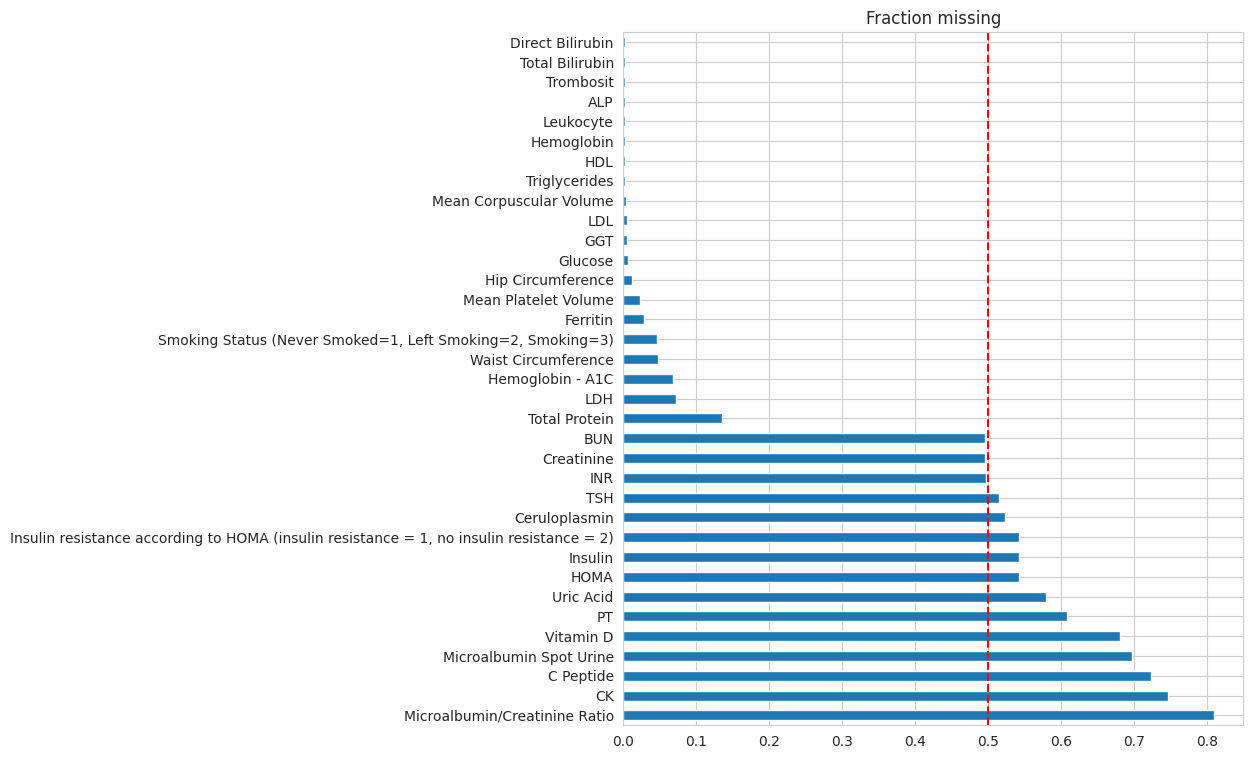

In [ ]:
# Working with missing values
miss = data[feature_cols].isna().mean().sort_values(ascending=False)
print(miss[miss > 0].round(3))

miss[miss > 0].plot(kind="barh", figsize=(8, 9))
plt.axvline(0.5, color="red", linestyle="--")
plt.title("Fraction missing"); plt.show()

In [ ]:
# Drop any column with roughly half or more of its values missing
drop_sparse = miss[miss > 0.45].index.tolist()   # adds INR, Creatinine, BUN
print(len(drop_sparse), "dropped:", drop_sparse)

model_features = [c for c in feature_cols if c not in drop_sparse]
print(len(model_features), "kept")   # expect 35

15 dropped: ['Microalbumin/Creatinine Ratio', 'CK', 'C Peptide', 'Microalbumin Spot Urine', 'Vitamin D', 'PT', 'Uric Acid', 'HOMA', 'Insulin', 'Insulin resistance according to HOMA (insulin resistance = 1, no insulin resistance = 2)', 'Ceruloplasmin', 'TSH', 'INR', 'Creatinine', 'BUN']
35 kept


In [ ]:
batch = ["INR", "BUN", "Creatinine", "PT", "Vitamin D", "TSH", "Ceruloplasmin", "Uric Acid", "Insulin"]
print(data[batch].notna().astype(int).corr().round(2))

                INR   BUN  Creatinine    PT  Vitamin D   TSH  Ceruloplasmin  \
INR            1.00  0.99        0.99  0.80       0.67  0.95           0.94   
BUN            0.99  1.00        1.00  0.79       0.67  0.95           0.94   
Creatinine     0.99  1.00        1.00  0.79       0.67  0.95           0.94   
PT             0.80  0.79        0.79  1.00       0.84  0.74           0.73   
Vitamin D      0.67  0.67        0.67  0.84       1.00  0.64           0.61   
TSH            0.95  0.95        0.95  0.74       0.64  1.00           0.94   
Ceruloplasmin  0.94  0.94        0.94  0.73       0.61  0.94           1.00   
Uric Acid      0.83  0.84        0.84  0.61       0.71  0.83           0.83   
Insulin        0.90  0.90        0.90  0.69       0.62  0.89           0.89   

               Uric Acid  Insulin  
INR                 0.83     0.90  
BUN                 0.84     0.90  
Creatinine          0.84     0.90  
PT                  0.61     0.69  
Vitamin D           0.71     

In [ ]:
panel = ["INR", "BUN", "Creatinine", "TSH", "Ceruloplasmin", "Insulin", "Uric Acid"]
data["n_panel"] = data[panel].notna().sum(axis=1)

print(data["n_panel"].value_counts().sort_index())
print(data.groupby("n_panel")["SigFibrosis"].agg(["mean", "count"]).round(3))

n_panel
0    299
3      3
4      6
5     14
6     58
7    225
Name: count, dtype: int64
          mean  count
n_panel              
0        0.251    299
3        0.333      3
4        0.333      6
5        0.786     14
6        0.448     58
7        0.462    225


Missingness in the extended laboratory variables was highly clustered: the tested/untested indicators for INR, BUN and creatinine had correlations of 0.99-1.00, and those for TSH, ceruloplasmin and insulin were 0.90-0.95 with them. These variables therefore reflect a single extended workup ordered for a selected subgroup with higher fibrosis prevalence, and they were excluded together to avoid learning referral behaviour.

In [ ]:
# do the two groups differ on the features you’re keeping?
data["in_panel"] = (data["n_panel"] >= 5).astype(int)

compare = ["Age", "Body Mass Index", "AST", "ALT", "GGT", "Trombosit", "Albumin", "Glucose", "Hemoglobin - A1C"]
print(data.groupby("in_panel")[compare].median().T.round(2))
print(data["in_panel"].value_counts())

# context only: severity of disease in each group
print(pd.crosstab(data["in_panel"], data["Fibrosis"], normalize="index").round(2))

in_panel               0       1
Age                47.00   47.00
Body Mass Index    30.46   32.01
AST                43.00   41.00
ALT                67.00   65.00
GGT                48.00   50.00
Trombosit         244.00  232.00
Albumin             4.80    4.60
Glucose            99.00  101.00
Hemoglobin - A1C    5.70    5.85
in_panel
0    308
1    297
Name: count, dtype: int64
Fibrosis     0     1     2     3     4
in_panel                              
0         0.43  0.32  0.15  0.08  0.02
1         0.22  0.31  0.22  0.20  0.06


In [ ]:
id_cols = ["Patient No.", "n_panel", "in_panel"]
feature_cols = [c for c in data.columns if c not in biopsy_cols + id_cols]
print(len(feature_cols))   # expect 50

50


In [ ]:
# 1. missing fraction on the full feature list
miss = data[feature_cols].isna().mean()

# 2. drop columns with ~50% or more missing (adds INR, Creatinine, BUN to the 12 above 50%)
drop_sparse = miss[miss > 0.45].index.tolist()

# 3. final feature list and type split
model_features = [c for c in feature_cols if c not in drop_sparse]
cat_like = [c for c in model_features if data[c].nunique() <= 3]
core_num = [c for c in model_features if c not in cat_like]

print(len(drop_sparse), "dropped")
print(len(model_features), "features |", len(core_num), "numeric |", len(cat_like), "coded")
print("Coded columns:", cat_like)

15 dropped
35 features | 29 numeric | 6 coded
Coded columns: ['Gender (Female=1, Male=2)', 'Diyabetes Mellitus (No=0, Yes=1)', 'Hypertension (No=0, Yes=1)', 'Hyperlipidemia (No=0, Yes=1)', 'Metabolic syndrome (No=0, Yes=1)', 'Smoking Status (Never Smoked=1, Left Smoking=2, Smoking=3)']


In [ ]:
from scipy.stats import mannwhitneyu

rows = []
for c in core_num:
    a = data.loc[data["SigFibrosis"] == 0, c].dropna()
    b = data.loc[data["SigFibrosis"] == 1, c].dropna()
    u = mannwhitneyu(a, b)
    rows.append((c, len(a) + len(b), round(a.median(), 2), round(b.median(), 2),
                 round(u.statistic / (len(a) * len(b)), 3), u.pvalue))

res = pd.DataFrame(rows, columns=["feature", "n_used", "median_no_fib", "median_fib", "AUC", "p_value"])
res["strength"] = (res["AUC"] - 0.5).abs()
res.sort_values("strength", ascending=False).drop(columns="strength").head(15)

,feature,n_used,median_no_fib,median_fib,AUC,p_value
0,Age,605,44.00,51.00,0.353,1.991926e-09
28,Hemoglobin - A1C,564,5.70,6.00,0.359,2.302323e-08
27,Glucose,601,98.00,105.00,0.376,4.753724e-07
23,Trombosit,604,247.50,220.50,0.618,1.536894e-06
11,GGT,602,46.00,56.00,0.396,2.196256e-05
3,Body Mass Index,605,30.79,32.39,0.400,4.611194e-05
5,Hip Circumference,598,103.00,106.00,0.408,1.783355e-04
25,Mean Platelet Volume,591,8.60,8.90,0.409,2.510763e-04
8,AST,605,39.00,44.00,0.411,2.694740e-04
1,Height,605,166.00,163.00,0.558,1.752826e-02


In [ ]:
# coded features vs. target (gender, diabetes, hypertension and so on)
for c in cat_like:
    print(c)
    t = pd.crosstab(data[c], data["SigFibrosis"])
    print(pd.concat([t, (t.div(t.sum(axis=1), axis=0)[1]).round(2).rename("fib_rate")], axis=1))
    print()

Gender (Female=1, Male=2)
                             0    1  fib_rate
Gender (Female=1, Male=2)                    
1                          169  115      0.40
2                          217  104      0.32

Diyabetes Mellitus (No=0, Yes=1)
                                    0    1  fib_rate
Diyabetes Mellitus (No=0, Yes=1)                    
0                                 284   96      0.25
1                                 102  123      0.55

Hypertension (No=0, Yes=1)
                              0    1  fib_rate
Hypertension (No=0, Yes=1)                    
0                           270  121      0.31
1                           116   98      0.46

Hyperlipidemia (No=0, Yes=1)
                                0    1  fib_rate
Hyperlipidemia (No=0, Yes=1)                    
0                             175   79      0.31
1                             211  140      0.40

Metabolic syndrome (No=0, Yes=1)
                                    0    1  fib_rate
Metabolic syndr

In [ ]:
# redundancy among features
corr = data[core_num].corr(method="spearman")
pairs = corr.abs().where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print(pairs[pairs > 0.7].sort_values(ascending=False).round(2))

AST                ALT                    0.84
Total Cholesterol  LDL                    0.81
Body Mass Index    Waist Circumference    0.76
                   Hip Circumference      0.75
Weight             Hip Circumference      0.74
dtype: float64


In [ ]:
print(data[["Body Mass Index", "Weight", "Height", "Waist Circumference", "Hip Circumference"]]
      .corr(method="spearman").round(2))

                     Body Mass Index  Weight  Height  Waist Circumference  \
Body Mass Index                 1.00    0.67   -0.29                 0.76   
Weight                          0.67    1.00    0.45                 0.55   
Height                         -0.29    0.45    1.00                -0.19   
Waist Circumference             0.76    0.55   -0.19                 1.00   
Hip Circumference               0.75    0.74    0.07                 0.67   

                     Hip Circumference  
Body Mass Index                   0.75  
Weight                            0.74  
Height                            0.07  
Waist Circumference               0.67  
Hip Circumference                 1.00  


In [ ]:
bmi_calc = data["Weight"] / (data["Height"] / 100) ** 2
diff = (bmi_calc - data["Body Mass Index"]).abs()

print(diff.describe().round(2))
print("Rows with |difference| > 1 BMI point:", (diff > 1).sum())
data.loc[diff > 1, ["Patient No.", "Height", "Weight", "Body Mass Index"]].assign(bmi_calc=bmi_calc.round(1)).head(10)

count    605.00
mean       0.03
std        0.16
min        0.00
25%        0.00
50%        0.00
75%        0.01
max        2.89
dtype: float64
Rows with |difference| > 1 BMI point: 3


,Patient No.,Height,Weight,Body Mass Index,bmi_calc
60,61,174,97,31.0,32.0
428,429,158,78,28.8,31.2
519,520,151,93,37.9,40.8


In [ ]:
data["BMI_calc"] = data["Weight"] / (data["Height"] / 100) ** 2
print((data["BMI_calc"] - data["Body Mass Index"]).abs().gt(1).sum())   # 3 before replacing

data["Body Mass Index"] = data["BMI_calc"].round(1)
data = data.drop(columns="BMI_calc")

3


Internal consistency was verified for derived variables. Body mass index matched weight/height² in 602 of 605 patients (within rounding); three discrepancies (≤2.9 BMI points) were resolved by recomputing BMI from height and weight. In contrast, the dataset’s pre-computed “at-risk NASH” flag disagreed with its own definition in 269 patients (44%) and was excluded.

In [ ]:
# the FIB-4 baseline
from sklearn.metrics import roc_auc_score

data["FIB4"] = (data["Age"] * data["AST"]) / (data["Trombosit"] * np.sqrt(data["ALT"]))
ok = data["FIB4"].notna()

print(data["FIB4"].describe().round(2))
print("FIB-4 AUC, significant fibrosis:", round(roc_auc_score(data.loc[ok, "SigFibrosis"], data.loc[ok, "FIB4"]), 3))
print("FIB-4 AUC, advanced fibrosis:  ", round(roc_auc_score(data.loc[ok, "AdvFibrosis"], data.loc[ok, "FIB4"]), 3))

id_cols = ["Patient No.", "n_panel", "in_panel", "FIB4"]   # keep FIB4 out of the model features


count    604.00
mean       1.21
std        0.77
min        0.26
25%        0.73
50%        1.04
75%        1.40
max        6.30
Name: FIB4, dtype: float64
FIB-4 AUC, significant fibrosis: 0.703
FIB-4 AUC, advanced fibrosis:   0.767


In [ ]:
from sklearn.metrics import roc_auc_score
rng = np.random.default_rng(42)

def boot_auc(y, s, n=2000):
    y, s = np.asarray(y), np.asarray(s)
    out = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            out.append(roc_auc_score(y[i], s[i]))
    return np.percentile(out, [2.5, 97.5]).round(3)

for t in ["SigFibrosis", "AdvFibrosis"]:
    print(t, "FIB-4 AUC 95% CI:", boot_auc(data.loc[ok, t], data.loc[ok, "FIB4"]))

# standard clinical cutoffs: 1.3 (rule out) and 2.67 (rule in)
for t in ["SigFibrosis", "AdvFibrosis"]:
    y = data.loc[ok, t]
    for cut in [1.3, 2.67]:
        pred = (data.loc[ok, "FIB4"] >= cut).astype(int)
        tp = ((pred == 1) & (y == 1)).sum(); fn = ((pred == 0) & (y == 1)).sum()
        tn = ((pred == 0) & (y == 0)).sum(); fp = ((pred == 1) & (y == 0)).sum()
        print(f"{t} @ FIB-4 >= {cut}: sensitivity {tp/(tp+fn):.2f}, specificity {tn/(tn+fp):.2f}, flagged {pred.mean():.0%}")

SigFibrosis FIB-4 AUC 95% CI: [0.66  0.744]
AdvFibrosis FIB-4 AUC 95% CI: [0.718 0.814]
SigFibrosis @ FIB-4 >= 1.3: sensitivity 0.50, specificity 0.78, flagged 32%
SigFibrosis @ FIB-4 >= 2.67: sensitivity 0.11, specificity 0.99, flagged 4%
AdvFibrosis @ FIB-4 >= 1.3: sensitivity 0.66, specificity 0.75, flagged 32%
AdvFibrosis @ FIB-4 >= 2.67: sensitivity 0.18, specificity 0.98, flagged 4%


FIB-4, a standard non-invasive fibrosis score, achieved an AUC of 0.703 for significant fibrosis and 0.767 for advanced fibrosis in this cohort (604 patients with complete inputs). These values serve as the benchmark against which the machine learning models are compared on identical data splits.